# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:

df = pd.read_csv("/content/listings.csv.gz")

df.head()



,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1352055619826961511,https://www.airbnb.com/rooms/1352055619826961511,20260914002229,2026-09-14,NaN,"New 3 bed, 1.5 bath",This stylish place to stay is perfect for grou...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,677651543,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,1215930899551057941,https://www.airbnb.com/rooms/1215930899551057941,20260914002229,2026-09-14,NaN,Queens apartament,Bring the whole family to this great place wit...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,392517036,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
2,1203866180302079266,https://www.airbnb.com/rooms/1203866180302079266,20260914002229,2026-09-15,NaN,Luxury Meets Comfort Stay NYC,This stylish place is close to must-see destin...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,115082911,...,NaN,NaN,NaN,NaN,NaN,2,0,2,0,NaN
3,15310580,https://www.airbnb.com/rooms/15310580,20260914002229,2026-09-15,previous scrape,Nice apartment in Gramercy.,Nice apartment in one of the best neighbors of NY,NaN,https://a0.muscache.com/pictures/c2c78aad-78c9...,27336207,...,4.88,5.00,4.25,NaN,NaN,2,2,0,0,0.07
4,32842295,https://www.airbnb.com/rooms/32842295,20260914002229,2026-09-15,previous scrape,Beautiful bedroom and full bathroom,NaN,NaN,https://a0.muscache.com/pictures/b946d6e3-07d6...,233227636,...,4.89,4.78,4.75,NaN,NaN,1,0,1,0,0.40


## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

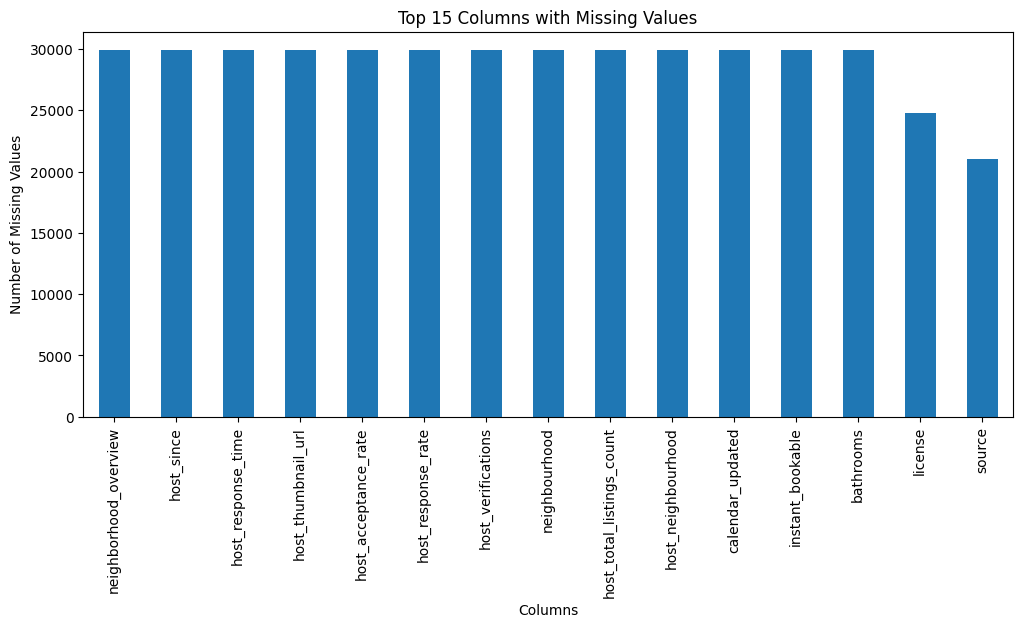

In [11]:
df.isnull().sum().sort_values(ascending=False).head(15).plot(kind="bar", figsize=(12, 5))

plt.title("Top 15 Columns with Missing Values")
plt.ylabel("Number of Missing Values")
plt.xlabel("Columns")
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. neighborhood_overview, host_since, and host_response_time

2. The one that would cause the biggest business issues would be host response times because you wouldnt' know how long it takes for hosts to respond which is a big part of customer service.

3.
I think that the neighboorhood overview could be dropped/ safely ignored as it doesn't have as many implications as the other ones.

## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [12]:

df.isnull().sum().sort_values(ascending=False).head(10)


,0
neighborhood_overview,29918
host_since,29918
host_response_time,29918
host_thumbnail_url,29918
host_acceptance_rate,29918
host_response_rate,29918
host_verifications,29918
neighbourhood,29918
host_total_listings_count,29918
host_neighbourhood,29918


### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. I would drop the host thumbnail url and neighboorhood overview

2.
They were not useful because they can't really be used for anything marketing or pricing or anything else.
3.
I think by leaving them in it would just cause confusion.



## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [14]:

df[["bedrooms", "bathrooms"]].isnull().sum()


df.shape[0]


29918

In [15]:

df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].median())

df["bathrooms"] = df["bathrooms"].fillna("Unknown")

df[["bedrooms", "bathrooms"]].isnull().sum()


,0
bedrooms,0
bathrooms,0


### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. I cleaned the bathroom and bedroom columns

2. For the bedroom column I used the median and for the bathroom column I filled them with "Unknown"

3. There's always a risk when cleaning with medians as it could skew the data a bit.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

In [18]:


df["price"] = df["price"].str.replace("$", "", regex=False)



In [19]:

df["price"] = pd.to_numeric(df["price"].str.replace(",", "", regex=False), errors="coerce")


### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1.

2.

3.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [17]:
print(df.duplicated().sum())

0


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1.I got no duplicates

2.

3. duplicates are risky because it could mean skewed data or doubled houses/ double bookings

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [ ]:
# export csv here 🔧

## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. __  
2. __  
3. __  
4. __  
5. __  


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [20]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_06_data_cleaning.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tru